Esse notebook tem como objetivo:
1. Caracterizar o laser utilizado para os experimentos no IDOR: $w_0$ (cintura do feixe), $z_R$ (comprimento de Rayleigh) e $z_0$ (distancia da cintura). Essa caracterização é feita para o feixe se propagando livremente, após a lente de bombeamento e do feixe contrapropagante (passando por todas as lentes).
2. Avaliar se as lentes utilizadas estão consistentes com as sugestões de otimização de acoplamento presentes no artigo "Optimizing the coupling efficiency of SPDC photon pairs into single-mode fibers". Mais abaixo serão apresentadas as condições ótimas de acordo com as previsões teóricas do artigo (as simulações foram feitas em outro notebook). Não as farei aqui, porque as funções definidas são longas. Para um futuro (talvez bem próximo) conseguirei exportar essas funções e fazer tudo bem aqui.
3. Caso as lentes utilizadas não forem consistentes com os resultados do artigo, determinar possíveis combinações de lentes.

---



In [4]:
import numpy as np
import matplotlib.pyplot as plt
import math
import pandas as pd
from scipy.optimize import curve_fit

## Caracterização do feixe se propagando livremente

O feixe foi medido em 5 posições, coletando 7 dados por posição. A posição do perfilomêtro está apresentada na imagem abaixo e corresponde aos números 1,2,3,4 e 5.

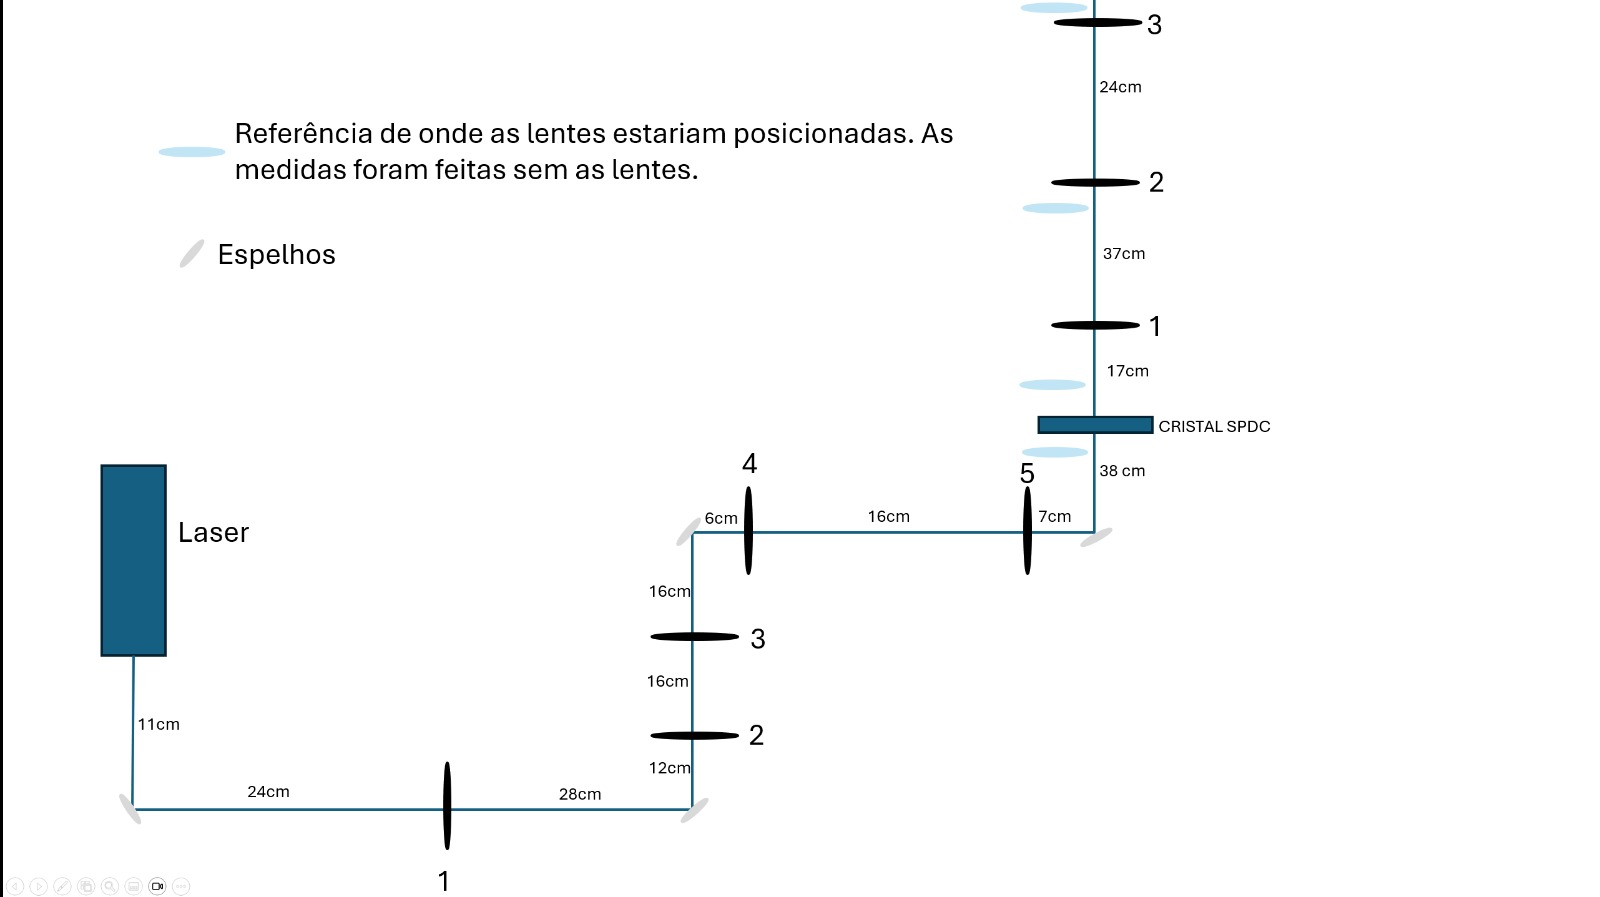


In [199]:
### Apartir da imagem acima:
z_livre = np.array([0, 40, 56, 78, 94])*1e-2 + (35e-2) # metros

In [200]:
livre1 = pd.read_csv("Data/Data-1-seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
livre2 = pd.read_csv("Data/Data-2-seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
livre3 = pd.read_csv("Data/Data-3-seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
livre4 = pd.read_csv("Data/Data-4-seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
livre5 = pd.read_csv("Data/Data-5-seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")

In [201]:
### Exemplo dos dados:
livre1.head()

,Measurement,Time [hh:mm:ss:zzz],Peak Position X[µm],Peak Position Y[µm],Centroid Position X[µm],Centroid Position Y[µm],AD Saturation[%],Total Power[dBm],Beam Width Clip X[µm],Beam Width Clip Y[µm],Gaussian Intensity X[%],Gaussian Intensity Y[%],Gaussian Diameter X[µm],Gaussian Diameter Y[µm],Unnamed: 14
0,1,10:40:10.100,-208.61,-134.92,-183.44,-92.26,67.68,20.85,750.96,914.65,95.53,95.47,793.63,936.24,NaN
1,2,10:40:20.075,-180.28,-189.23,-184.35,-104.05,72.93,21.06,780.74,863.09,95.82,95.25,784.58,936.61,NaN
2,3,10:40:30.081,-149.59,-111.31,-176.06,-99.74,68.30,20.97,740.69,912.77,95.77,95.45,765.84,938.80,NaN
3,4,10:40:40.081,-227.50,-98.33,-184.74,-97.63,66.32,20.91,751.36,917.23,95.81,95.35,774.97,955.89,NaN
4,5,10:40:50.081,-182.12,-130.20,-170.01,-92.97,69.85,20.92,761.04,879.89,95.81,95.38,778.47,952.20,NaN


In [202]:
files = [livre1, livre2, livre3, livre4, livre5]


def beam_waist(files):
    wX, wY = [],[]
    std_wX, std_wY = [], []
    if len(files )>1:
        for df in files:
            rx = df['Gaussian Diameter X[µm]']/2
            ry = df['Gaussian Diameter Y[µm]']/2
            
            wX.append(rx.mean()) 
            wY.append(ry.mean()) 
            std_wX.append(rx.std()) 
            std_wY.append(ry.std()) 
        wX = np.array(wX)
        wY = np.array(wY)
        std_wY = np.array(std_wY)
        std_wX = np.array(std_wX)        
    return wX, wY,std_wY,std_wX


w_X, w_Y,std_wY,std_wX = beam_waist(files)

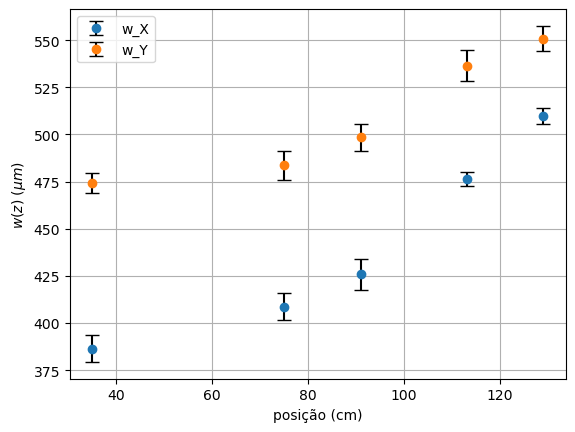

In [203]:
### Vamos plotar um exemplo:
plt.errorbar(z_livre*1e2, w_X, yerr = std_wX, fmt='o', ecolor='black', capsize=5, label = 'w_X')
plt.errorbar(z_livre*1e2, w_Y, yerr = std_wY, fmt='o', ecolor='black', capsize=5, label = 'w_Y')

plt.legend()
plt.grid()

plt.xlabel('posição (cm)')
plt.ylabel(r'$w(z)$ ($\mu m$)')

plt.show()

Agora vamos definir uma função que será usada nas outras caracterizações também. Essa função servirá para ajustar os nossos dados, com base na suposição que os feixes são gaussianos. A partir dessa suposição e do ajuste seremos capazes de encontrar os parâmetros desejados.

A teoria nos diz que a cintura do feixe se propaga no eixo $z$ descrito pela equação

$$
w(z) = w_0 \sqrt{1 + (\frac{z - z_0}{z_R})^2}
$$

Em que,
* $w_0$: cintura do feixe no mínimo;
* $z_0$: posição do $w_0$ (medido a partir da saída do laser);
* $z_R$: comprimento de Rayleigh;

Sendo assim faremos um ajuste de 3 parâmetros: $w_0$, $z_0$ e $z_R$. Poderemos também definir a divergência de nosso feixe:

$$
\theta = \frac{w_0}{z_R}
$$

Tendo obtido esses dados poderemos verificar a qualidade de nosso feixe, grandeza que será importante para os próximos ajustes realizados. Essa grandeza é o $M^2$, construimos ela considerando que existe um feixe gaussiano ideal (a partir da toeria de feixes gaussianos) e comparamos os resultados obtidos.

$$
M^2 = \frac{\pi w_0^2}{\lambda z_R}
$$

Embora não seja ideal ajustar três parâmetros ao mesmo tempo, vamos fazer isso para evitar de restrigir os valores obtidos de acordo com a teoria de feixes gaussianos ideais. Acredito que o ajuste não será tão prejudicado por isso, já que as medições foram bem distribuídas.

**Dúvida: O cálculo da divergência é feito usando uma fórmula baseada na ideia de que z>>$z_r$ e o termo na equação de W(z) pode ser negligenciado. Isso não me parece valer aqui.**

In [204]:
def gaussian_beam(z, w0, z0, zR, wavelength=325e-9, M2=None):
    if M2 is not None:
        zR = np.pi * w0**2 / (wavelength * M2)

    return w0 * np.sqrt(1 + ((z - z0) / zR)**2)


def gaussian_fit(w_X, w_Y, std_wX, std_wY, z,
                 wavelength=325e-9, M2_X=None, M2_Y=None):

    wx = np.array(w_X) * 1e-6
    wy = np.array(w_Y) * 1e-6

    sx = np.array(std_wX) * 1e-6
    sy = np.array(std_wY) * 1e-6

    # Fit each axis
    def fit_axis(w, sigma, M2):

        if M2 is None:
            # Fit w0, z0 and zR freely
            def model(z, w0, z0, zR):
                return gaussian_beam(z, w0, z0, zR, wavelength)

            p0 = [w.min(), -0.05, 2.0]
            bounds = (
                [1e-9, -np.inf, 1e-6],
                [np.inf, np.inf, np.inf]
            )

        else:
            # zR is restricted by M2 inside gaussian_beam
            def model(z, w0, z0):
                return gaussian_beam(z, w0, z0, None, wavelength, M2)

            p0 = [w.min(), -0.05]
            bounds = (
                [1e-9, -np.inf],
                [np.inf, np.inf]
            )

        popt, pcov = curve_fit(
            model, z, w,
            p0=p0,
            bounds=bounds,
            sigma=sigma,
            absolute_sigma=True,
            maxfev=20000
        )

        if M2 is None:
            w0, z0, zR = popt
        else:
            w0, z0 = popt
            zR = np.pi * w0**2 / (wavelength * M2)

        return w0, z0, zR

    # Fit X and Y
    w0_X, z0_X, zR_X = fit_axis(wx, sx, M2_X)
    w0_Y, z0_Y, zR_Y = fit_axis(wy, sy, M2_Y)

    # Divergence (in radians)
    divergence_X = w0_X / zR_X
    divergence_Y = w0_Y / zR_Y

    # Convert to milliradians
    divergence_X_mrad = divergence_X * 1000
    divergence_Y_mrad = divergence_Y * 1000

    # M²
    M2_X = np.pi * w0_X**2 / (wavelength * zR_X)
    M2_Y = np.pi * w0_Y**2 / (wavelength * zR_Y)

    return (w0_X, w0_Y, z0_X, z0_Y, zR_X, zR_Y,
            divergence_X_mrad, divergence_Y_mrad, M2_X, M2_Y)

Direção X:
  Raio da cintura w0 = 385.77 µm
  Posição da cintura z0 = 387.991 mm
  Comprimento de Rayleigh zR = 1037.343 mm
M^2 = 1.39
  Divergência = 0.372 mrad (0.0156°)

Direção Y:
  Raio da cintura w0 = 473.21 µm
  Posição da cintura z0 = 421.761 mm
  Comprimento de Rayleigh zR = 1427.071 mm
M^2 = 1.52
  Divergência = 0.332 mrad (0.0157°)


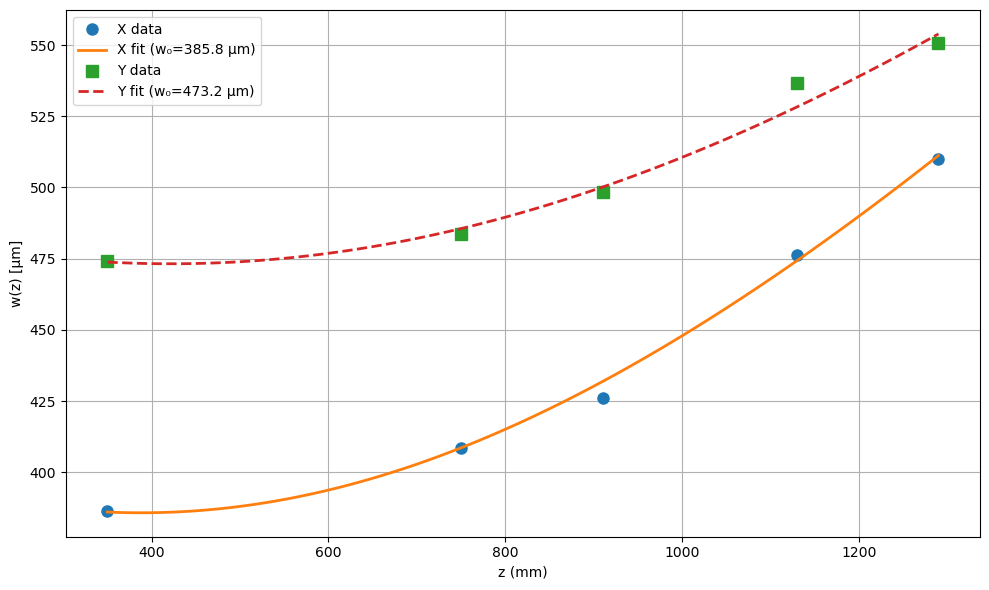

In [205]:
w0_X,w0_Y,z0_X,z0_Y,zR_X,zR_Y,divergence_X_mrad,divergence_Y_mrad,M2_X,M2_Y = gaussian_fit(w_X,w_Y,std_wX, std_wY,z_livre)

print("Direção X:")
print(f"  Raio da cintura w0 = {w0_X*1e6:.2f} µm")
print(f"  Posição da cintura z0 = {z0_X*1e3:.3f} mm")
print(f"  Comprimento de Rayleigh zR = {zR_X*1e3:.3f} mm")
print(f"M^2 = {M2_X:.2f}")
print(f"  Divergência = {divergence_X_mrad:.3f} mrad ({np.degrees(divergence_X):.4f}°)")

print("\nDireção Y:")
print(f"  Raio da cintura w0 = {w0_Y*1e6:.2f} µm")
print(f"  Posição da cintura z0 = {z0_Y*1e3:.3f} mm")
print(f"  Comprimento de Rayleigh zR = {zR_Y*1e3:.3f} mm")
print(f"M^2 = {M2_Y:.2f}")
print(f"  Divergência = {divergence_Y_mrad:.3f} mrad ({np.degrees(divergence_Y):.4f}°)")

# Plot
z_fit = np.linspace(z_livre.min(), z_livre.max(), 100)
plt.figure(figsize=(10, 6))
plt.plot(z_livre*1e3, w_X, 'o', label='X data', markersize=8)
plt.plot(z_fit*1e3, gaussian_beam(z_fit, w0_X,z0_X,zR_X)*1e6, '-', label=f'X fit (w₀={w0_X*1e6:.1f} µm)', linewidth=2)
plt.plot(z_livre*1e3, w_Y, 's', label='Y data', markersize=8)
plt.plot(z_fit*1e3, gaussian_beam(z_fit, w0_Y,z0_Y,zR_Y)*1e6, '--', label=f'Y fit (w₀={w0_Y*1e6:.1f} µm)', linewidth=2)
plt.xlabel('z (mm)')
plt.ylabel('w(z) [µm]')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

### Parâmetros do feixe Gaussiano

| Parâmetro | Direção X | Direção Y |
|---|---:|---:|
| Raio da cintura ($w_0$) | 385.77 µm | 473.21 µm |
| Posição da cintura ($z_0$) | 38.8 cm | 42.2 cm |
| Comprimento de Rayleigh ($z_R$) | 1.04 m | 1.43 m |
| Divergência ($\theta$) | 0.372 mrad | 0.332 mrad |
| Divergência (°) | 0.0213° | 0.0190° |
| $M^2$ | 1.39 | 1.52 |

Embora a grande maioria dos parâmetros tenham valores razoáveis, de acordo com o spec-sheet a divergência ideal seria 0.11mrad . Porém, ainda está no limite (0.5mrad).

## Determinação da eficiência de acoplamento

Faltam ainda os dados para depois da lente de coleta e do feixe contra-propagante. Mas podemos checar a distância focal da lente de bombeio baseado na razão $Z_{R_P}/L$. 

Um ponto importante é que os cálculos a seguir assumem um feixe gaussiano e que os elementos ópticos estão na cintura $w_0$ do feixe. É bem claro que eles não estão na cintura, mas como o feixe tem uma divergência pequena, podemos justificar que será aceitável considerar que o elemento óptico está suficientemente perto da cintura, desde que ele esteja na profundidade de foco do laser (dentro de um comprimento de Rayleigh). Isso significa que $W(z) \leq \sqrt{2}W_0$. A distância da lente do laser é de $1,49m$ e o aceitável é $1,64m$. Poderíamos retornar um pouco essa lente, para talvez melhor validar as conclusões. 

Para uma lente colocada na cintura de um feixe Gaussiano podemos dizer que:

$$
W_0' = \frac{W_0}{\sqrt{1 + (z_0/f)^2}}
$$

Nesse caso, podemos usar essa aproximação, porque nosso feixe está colimado. E pelas nossas medições o comprimento de Rayleigh desse feixe é de 1m aproximadamente, portanto estamos pela cintura dele.


E para o caso especial, em que a profundidade de foco ($2z_0$) é muito maior que a distância focal da lente podemos fazer a aproximaçáo:
$$
W_0' = \frac{\lambda}{\pi W_0}f
$$

Note que, é óbvio que isso também vale. A profundidade de foco do feixe é aproximadamente $2m$ e com toda certeza nossa lente terá uma distância focal na ordem de cm's.

Sendo que,
$$
W_0 = \sqrt{\frac{\lambda z_0}{\pi}}
$$

Assim podemos relacionar o tamanho da cintura com o comprimento de Rayleigh. Nessa etapa sabemos qual a distância focal utilizada no laboratório e, portanto, iremos estimar o comprimento de rayleigh que nos dá a lente desejada.

In [139]:
### De nossas medições conseguimos determinar:
lam_pump = 325e-9 #m
crystal_L = 2e-3 #m
w_0 = 430.49e-6 #m


# definir funcoes para calcular:
calc_z0 = lambda lam, w0 : (np.pi *w0**2)/(lam)
calc_W0 = lambda lam,z0: np.sqrt((lam*z0)/np.pi)


z0 = 1.23

new_z0 = 17.5*crystal_L ### Z_Rp/L = 17.5

new_w0 = calc_W0(lam_pump, new_z0)

In [140]:
print('Comprimento de Rayleigh:')
print(z0 * 1e3, 'mm')
print(new_z0*1e3, 'mm')
print(30*'--')
print('Cintura do feixe (raio):')
print(w_0 * 1e6, 'µm')
print(new_w0*1e6, 'µm')

Comprimento de Rayleigh:
1230.0 mm
35.0 mm
------------------------------------------------------------
Cintura do feixe (raio):
430.49 µm
60.17287557812589 µm


In [141]:
define_f = lambda w0, w0new, lam: (w0*w0new*np.pi)/lam
lens_f = define_f(w_0,new_w0,lam_pump)

print(f'Focusing lens f = {lens_f*1e3:.2f}mm')

Focusing lens f = 250.40mm


Ou seja, determinamos que para obtermos a lente de bombeio com $f = 250$mm é necessário ter $Z_{R_P}/L = 17.5$. Ainda vamos determinar qual o $Z_{R_C}/L$ com as lentes atuais para poder estimar o $\eta_C$.

Deixamos aqui as livres e especificaremos a razão desejada (que está diretamente relacionada com a cintura do feixe).



Já a fibra que temos é uma P1-630A-FC2, cujo Mode-Field Diameter é entre $3.6 \mu \text{m} $ e $5.3 \mu \text{m}$. Vamos considerar um valor intermediário de $4.45 \mu \text{m}$. A partir disso conseguimos determinar o diametro do feixe gaussiano contra-propagante:


$$
MFD = 2W_f → W_f = 2.225 \mu \text{m}
$$


Seguindo o caminho do contra-propagante, o feixe encontra uma lente asférica, assim:


$$
W_a = \frac{\lambda f_a}{\pi W_f}
$$

Após passar pela lente asférica o tamanho do feixe contra-propagante aumenta (e o feixe que está vindo do cristal diminui para o tamanho desejado de $W_f$). Logo note que aqui garantimos que o tamanho de distância focal a ser calculada sempre estará limitada pelo tamanho do feixe que adentra a fibra.


Podemos ainda supor $f$ a partir das especificações das lentes disponíveis. O feixe segue e encontra um sistema $4f$, que tem como função ajustar o tamanho desse feixe. Esse ponto conecta o $W'_C$ (associado a $z_{R_C}$ e a distância focal almejada) e W_a:

$$
\frac{W'_C}{W_a} = \frac{f_1}{f_2}
$$

Então, como $W'_C$:
$$
f = \frac{W_C * W'_C \pi}{\lambda}
$$
$$
f = W_a\frac{f_1}{f_2}W_C \frac{\pi}{\lambda}
$$
Por fim substituindo W_a:

$$
f = f_a \frac{f_1}{f_2}\frac{W_c}{W_f}
$$

Sendo que $W_C$ e $W_f$ são conhecidos e podemos fazer as escolhas mais razoáveis para o resto.

In [160]:
import ipywidgets as widgets
from IPython.display import display


lam = 650e-9          # wavelength [m]
crystal_L = 2e-3      # Rayleigh length target z_R,C [m]

# Fiber mode field diameter
MFD = 4.5e-6          # [m]
W_f = MFD / 2         # Gaussian mode radius [m]


def lens_f(fa, f1, f2, W_C, W_f):

    return fa * (f2 / f1) * (W_C / W_f)


def collimated_beam_after_asphere(lam, fa, W_f):
    """
    Radius of the approximately collimated Gaussian beam
    produced by the aspherical lens.

    fa must be in meters.
    """
    return lam * fa / (np.pi * W_f)

z_R_C = 0.89* crystal_L
W_C = calc_W0(lam, z_R_C)

print(f"Target Rayleigh length z_R,C = {z_R_C*1e3:.2f} mm")
print(f"Target collection waist W_C = {W_C*1e6:.2f} µm")
print(f"Fiber mode radius W_f = {W_f*1e6:.2f} µm")
print(f"W_C / W_f = {W_C/W_f:.3f}")

Target Rayleigh length z_R,C = 1.78 mm
Target collection waist W_C = 19.19 µm
Fiber mode radius W_f = 2.25 µm
W_C / W_f = 8.529


In [161]:
# ============================================================
# INTERACTIVE LENS EXPLORER
# ============================================================

def interactive_lens_system(fa_mm, f1_mm, f2_mm):

    # Convert mm -> m where necessary
    fa = fa_mm * 1e-3

    # 4f magnification
    M = f2_mm / f1_mm

    # Beam radius after the aspherical lens
    W_asphere = collimated_beam_after_asphere(lam,fa,W_f)

    # Beam radius after the 4f telescope
    W_after_4f = W_asphere * M

    # Required collection-lens focal length
    # Since fa, f1, f2 are all entered in mm,
    # output is also in mm.
    f_C_mm = lens_f(fa_mm,f1_mm,f2_mm,W_C,W_f)

    print("==============================================")
    print("          COLLECTION SYSTEM DESIGN")
    print("==============================================")
    print()
    print(f"Wavelength                  = {lam*1e9:.1f} nm")
    print(f"Target Rayleigh length      = {z_R_C*1e3:.2f} mm")
    print()
    print(f"Fiber MFD                   = {MFD*1e6:.2f} µm")
    print(f"Fiber mode radius W_f       = {W_f*1e6:.2f} µm")
    print()
    print(f"Target collection waist W_C = {W_C*1e6:.2f} µm")
    print()
    print("----------------------------------------------")
    print(f"Aspherical lens f_a         = {fa_mm:.1f} mm")
    print(f"4f lens f1                  = {f1_mm:.1f} mm")
    print(f"4f lens f2                  = {f2_mm:.1f} mm")
    print()
    print(f"4f magnification f2/f1      = {M:.3f}")
    print()
    print(f"Beam radius before asphere   = {W_asphere*1e3:.3f} mm")
    print(f"Beam diameter before asphere = {2*W_asphere*1e3:.3f} mm")
    print()
    print(f"Beam radius before 4f        = {W_after_4f*1e3:.3f} mm")
    print(f"Beam diameter before 4f      = {2*W_after_4f*1e3:.3f} mm")
    print()
    print("----------------------------------------------")
    print(f"Required collection lens:")
    print()
    print(f"        f_C = {f_C_mm:.2f} mm")
    print()
    print("==============================================")


# ============================================================
# SLIDERS
# ============================================================

fa_widget = widgets.SelectionSlider(
    options=[11],
    value=11,
    description='f_a [mm]:',
    continuous_update=False,
    style={'description_width': '100px'},
    layout=widgets.Layout(width='600px')
)

f1_widget = widgets.SelectionSlider(options  = [25.4, 35,75,  100,125,200,250, 300,400, 500, 750 ],value=100,
    description='f1 [mm]:',
    continuous_update=False,
    style={'description_width': '100px'},
    layout=widgets.Layout(width='600px')
)

f2_widget =  widgets.SelectionSlider(options  = [25.4, 35,75,  100,125,200,250, 300,400, 500, 750 ],value=100,
                                     description='f2 [mm]:',
                                     continuous_update=False,
                                     style={'description_width': '100px'},
                                     layout=widgets.Layout(width='600px'))


# ============================================================
# DISPLAY
# ============================================================

widgets.interact(
    interactive_lens_system,
    fa_mm=fa_widget,
    f1_mm=f1_widget,
    f2_mm=f2_widget
);

interactive(children=(SelectionSlider(continuous_update=False, description='f_a [mm]:', layout=Layout(width='6…

Com base nos cálculos com as lentes atuais temos que $Z_{R_C}/L = 0.89$ . Sendo assim, utilizando o código do Schwaller, podemos definir
$$
\eta_C(Z_{R_P}/L = 17.5, Z_{R_C}/L = 0.89) = 0.98
$$

Graficamente, fixando em cada caso uma das razões:


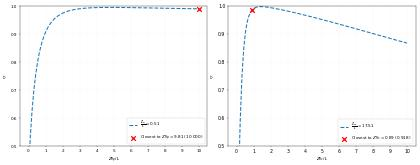



Agora temos que garantir que o **cristal está posicionado na cintura do feixe**. Além disso, aproveitaremos para verificar se realmente $Z_{R_C}/L = 0.89$ (a partir do ajuste de $w'$).

Os feixes têm cinturas com raio e comprimento de Rayleigh esperados de:

Bombeio:
$$
w_P = 60.17\mu m \\
z_{R_P} = 35 mm
$$
Já na coleta:
$$
w_C = 19.17\mu m \\
z_{R_P} = 1.78 mm
$$

Vamos primeiro checar o propagante:

In [250]:
z_pos = np.array([i*2.5*1e-2 for i in range(0,7) ]) +(25+15+ 2.5)*1e-2

In [251]:
coleta1 = pd.read_csv("Data_2110_325/M1_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
coleta2 = pd.read_csv("Data_2110_325/M2_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
coleta3 = pd.read_csv("Data_2110_325/M3_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
coleta4 = pd.read_csv("Data_2110_325/M4_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
coleta5 = pd.read_csv("Data_2110_325/M5_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
coleta6 = pd.read_csv("Data_2110_325/M6_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
coleta7 = pd.read_csv("Data_2110_325/M7_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")

In [252]:
coleta1.head()

,Measurement,Time [hh:mm:ss:zzz],Peak Position X[µm],Peak Position Y[µm],Centroid Position X[µm],Centroid Position Y[µm],AD Saturation[%],Total Power[dBm],Beam Width Clip X[µm],Beam Width Clip Y[µm],Gaussian Intensity X[%],Gaussian Intensity Y[%],Gaussian Diameter X[µm],Gaussian Diameter Y[µm],Unnamed: 14
0,1,13:51:00.629,-187.36,-133.74,-220.38,-159.62,62.79,-0.09,803.82,875.79,95.54,94.97,856.44,933.28,NaN
1,2,13:51:01.610,-164.93,-170.34,-233.94,-155.26,61.92,0.09,819.95,898.32,95.63,95.35,874.33,937.07,NaN
2,3,13:51:02.609,-157.85,-97.38,-229.44,-136.67,59.42,-0.05,796.38,907.41,95.71,95.21,845.47,935.32,NaN
3,4,13:51:03.610,-205.07,-175.06,-226.56,-143.36,61.26,-0.02,775.65,854.20,95.66,95.10,833.10,932.72,NaN
4,5,13:51:04.611,-147.23,-169.57,-228.55,-149.98,62.51,0.05,791.52,883.61,95.53,94.93,836.28,932.69,NaN


In [253]:
files = [coleta1, coleta2, coleta3, coleta4, coleta5, coleta6, coleta7]
w_X, w_Y,std_wY,std_wX = beam_waist(files)

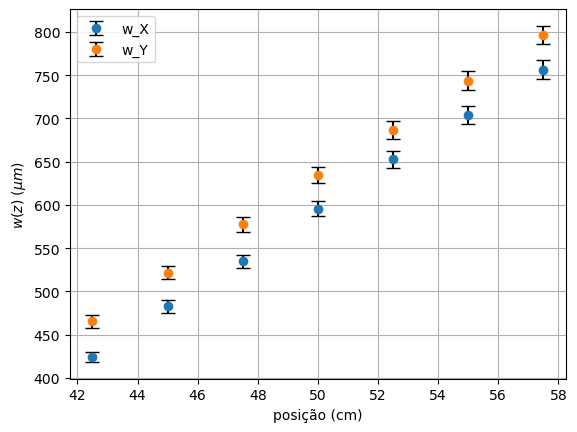

In [254]:
### Vamos plotar um exemplo:
plt.errorbar(z_pos*1e2, w_X, yerr = std_wX, fmt='o', ecolor='black', capsize=5, label = 'w_X')
plt.errorbar(z_pos*1e2, w_Y, yerr = std_wY, fmt='o', ecolor='black', capsize=5, label = 'w_Y')

plt.legend()
plt.grid()

plt.xlabel('posição (cm)')
plt.ylabel(r'$w(z)$ ($\mu m$)')

plt.show()

Direção X:
  Raio da cintura w0 = 63.79 µm
  Posição da cintura z0 = 237.927 mm
  Comprimento de Rayleigh zR = 28.364 mm
  Divergência = 2.249 mrad (0.0156°)

Direção Y:
  Raio da cintura w0 = 70.48 µm
  Posição da cintura z0 = 217.862 mm
  Comprimento de Rayleigh zR = 31.654 mm
  Divergência = 2.226 mrad (0.0157°)


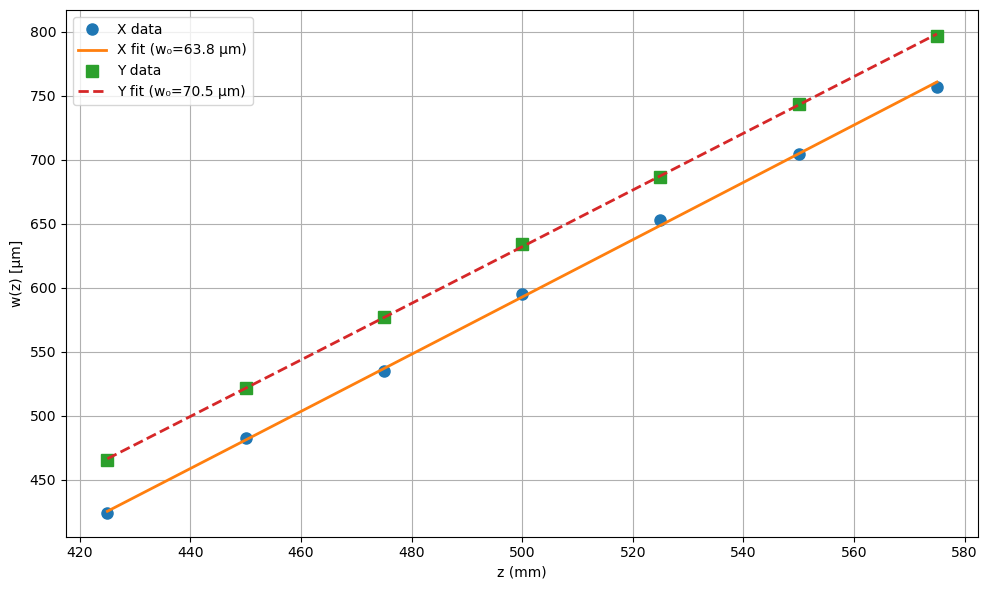

In [255]:
w0_X,w0_Y,z0_X,z0_Y,zR_X,zR_Y,divergence_X_mrad,divergence_Y_mrad,M2_X,M2_Y = gaussian_fit(w_X,w_Y,std_wX, std_wY,z_pos,M2_X = M2_X, M2_Y = M2_Y )

print("Direção X:")
print(f"  Raio da cintura w0 = {w0_X*1e6:.2f} µm")
print(f"  Posição da cintura z0 = {z0_X*1e3:.3f} mm")
print(f"  Comprimento de Rayleigh zR = {zR_X*1e3:.3f} mm")
print(f"  Divergência = {divergence_X_mrad:.3f} mrad ({np.degrees(divergence_X):.4f}°)")

print("\nDireção Y:")
print(f"  Raio da cintura w0 = {w0_Y*1e6:.2f} µm")
print(f"  Posição da cintura z0 = {z0_Y*1e3:.3f} mm")
print(f"  Comprimento de Rayleigh zR = {zR_Y*1e3:.3f} mm")
print(f"  Divergência = {divergence_Y_mrad:.3f} mrad ({np.degrees(divergence_Y):.4f}°)")

# Plot
z_fit = np.linspace(z_pos.min(), z_pos.max(), 100)
plt.figure(figsize=(10, 6))
plt.plot(z_pos*1e3, w_X, 'o', label='X data', markersize=8)
plt.plot(z_fit*1e3, gaussian_beam(z_fit, w0_X,z0_X,zR_X)*1e6, '-', label=f'X fit (w₀={w0_X*1e6:.1f} µm)', linewidth=2)
plt.plot(z_pos*1e3, w_Y, 's', label='Y data', markersize=8)
plt.plot(z_fit*1e3, gaussian_beam(z_fit, w0_Y,z0_Y,zR_Y)*1e6, '--', label=f'Y fit (w₀={w0_Y*1e6:.1f} µm)', linewidth=2)
plt.xlabel('z (mm)')
plt.ylabel('w(z) [µm]')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

### Parâmetros do Feixe Gaussiano após lente de bombeio:


| Parâmetro | Direção X | Direção Y |
|---|---:|---:|
| Raio da cintura ($w_0$) | 63.79 µm | 70.48 µm |
| Posição da cintura ($z_0$) | 237.927 mm | 217.862 mm |
| Comprimento de Rayleigh ($z_R$) | 28.364 mm | 31.654 mm |
| Divergência ($\theta$) | 2.249 mrad | 2.226 mrad |
| Divergência (°) | 0.1289° | 0.1275° |


Ou seja, note que nosso cristal não está na cintura do feixe! Podemos calcular a cintura do feixe na distância focal da lente. 

In [256]:
print(f'Cintura do feixe gaussiano na distância focal da lente (25cm) no eixo X: {gaussian_beam(250e-3, w0_X,z0_X,zR_X)*1e6:.2f}µm') 
print(f'Cintura do feixe gaussiano na distância focal da lente (25cm) no eixo Y: {gaussian_beam(250e-3, w0_Y,z0_Y,zR_Y)*1e6:.2f}µm') 

Cintura do feixe gaussiano na distância focal da lente (25cm) no eixo X: 69.33µm
Cintura do feixe gaussiano na distância focal da lente (25cm) no eixo Y: 100.43µm


Esse resultado NÃO é compatível com o valor medido hoje pelo Thiago. Ele mediu uma cintura de X: $44,59 \mu m$ e Y: $43.825 \mu m $

A distância em ambos os casos (X, Y) da cintura ao cristal é de 13cm e 33cm.

--------
Dúvida: os dados crescem linearmente, eu suponho que seja, porque estamos pegando um trecho muito pequeno dessa curva que descreve o feixe, afinal uma parabola se vista de muito perto é uma reta, por exemplo. Isso talvez possa afetar nosso ajuste.

## Definição dos parâmetros para o feixe contra-propagante

In [177]:
contra1 = pd.read_csv("Data_2110_650/M1_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
contra2 = pd.read_csv("Data_2110_650/M2_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
contra3 = pd.read_csv("Data_2110_650/M3_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
contra4 = pd.read_csv("Data_2110_650/M4_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
contra5 = pd.read_csv("Data_2110_650/M5_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
contra6 = pd.read_csv("Data_2110_650/M6_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
contra0 = pd.read_csv("Data_2110_650/M7_seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
# 7 foi descartado porque deu problema na medicao do diametro

In [178]:
z_contra = np.array([5.6, 7.5,10,13.3,15.,17.3,19.8 ])*1e-2 +  4e-2

In [179]:
contra7.head()

,Measurement,Time [hh:mm:ss:zzz],Peak Position X[µm],Peak Position Y[µm],Centroid Position X[µm],Centroid Position Y[µm],AD Saturation[%],Total Power[dBm],Beam Width Clip X[µm],Beam Width Clip Y[µm],Gaussian Intensity X[%],Gaussian Intensity Y[%],Gaussian Diameter X[µm],Gaussian Diameter Y[µm],Unnamed: 14
0,1,16:10:22.020,-290.07,-447.77,-195.37,-310.01,50.20,9.69,967.22,1432.84,95.50,94.52,997.69,1217.44,NaN
1,2,16:10:23.007,-288.89,-445.40,-195.46,-309.69,50.63,9.67,968.38,1433.48,95.47,94.53,997.47,1217.26,NaN
2,3,16:10:24.005,-301.88,-443.04,-195.40,-309.21,50.50,9.68,967.66,1439.30,95.47,94.54,998.79,1217.93,NaN
3,4,16:10:25.007,-307.78,-443.04,-195.15,-309.69,50.60,9.68,976.98,1434.97,95.47,94.50,998.93,1218.57,NaN
4,5,16:10:26.007,-306.60,-450.13,-195.20,-308.49,50.25,9.67,976.19,1432.13,95.47,94.55,998.75,1217.69,NaN


In [183]:
files = [contra7, contra1, contra2, contra3, contra4, contra5, contra6]

w_X, w_Y, std_wX, std_wY = beam_waist(files)


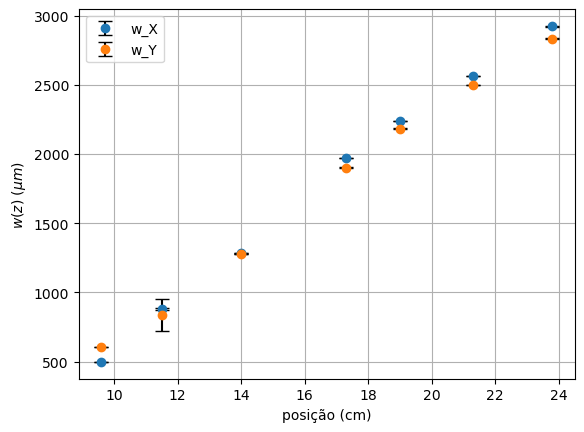

In [184]:
# Vamos plotar um exemplo:
plt.errorbar(z_contra*1e2, w_X, yerr = std_wX, fmt='o', ecolor='black', capsize=5, label = 'w_X')
plt.errorbar(z_contra*1e2, w_Y, yerr = std_wY, fmt='o', ecolor='black', capsize=5, label = 'w_Y')

plt.legend()
plt.grid()

plt.xlabel('posição (cm)')
plt.ylabel(r'$w(z)$ ($\mu m$)')

plt.show()

Direção X:
  Raio da cintura w0 = 5.74 µm
  Posição da cintura z0 = 68.197 mm
  Comprimento de Rayleigh zR = 0.319 mm
M^2 = 1.00
  Divergência = 18.011 mrad (0.0156°)

Direção Y:
  Raio da cintura w0 = 6.44 µm
  Posição da cintura z0 = 58.173 mm
  Comprimento de Rayleigh zR = 0.401 mm
M^2 = 1.00
  Divergência = 16.071 mrad (0.0157°)


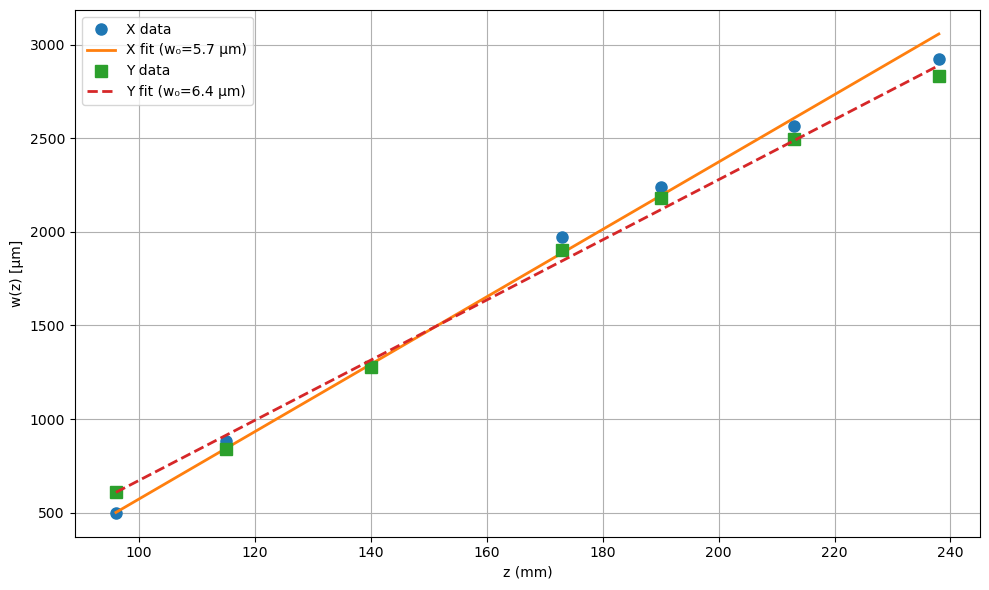

In [188]:
w0_X,w0_Y,z0_X,z0_Y,zR_X,zR_Y,divergence_X_mrad,divergence_Y_mrad,M2_X,M2_Y = gaussian_fit(w_X,w_Y,std_wX, std_wY,z_contra, M2_X = 1, M2_Y = 1)

print("Direção X:")
print(f"  Raio da cintura w0 = {w0_X*1e6:.2f} µm")
print(f"  Posição da cintura z0 = {z0_X*1e3:.3f} mm")
print(f"  Comprimento de Rayleigh zR = {zR_X*1e3:.3f} mm")
print(f"M^2 = {M2_X:.2f}")
print(f"  Divergência = {divergence_X_mrad:.3f} mrad ({np.degrees(divergence_X):.4f}°)")

print("\nDireção Y:")
print(f"  Raio da cintura w0 = {w0_Y*1e6:.2f} µm")
print(f"  Posição da cintura z0 = {z0_Y*1e3:.3f} mm")
print(f"  Comprimento de Rayleigh zR = {zR_Y*1e3:.3f} mm")
print(f"M^2 = {M2_Y:.2f}")
print(f"  Divergência = {divergence_Y_mrad:.3f} mrad ({np.degrees(divergence_Y):.4f}°)")

# Plot
z_fit = np.linspace(z_contra.min(), z_contra.max(), 100)
plt.figure(figsize=(10, 6))
plt.plot(z_contra*1e3, w_X, 'o', label='X data', markersize=8)
plt.plot(z_fit*1e3, gaussian_beam(z_fit, w0_X,z0_X,zR_X)*1e6, '-', label=f'X fit (w₀={w0_X*1e6:.1f} µm)', linewidth=2)
plt.plot(z_contra*1e3, w_Y, 's', label='Y data', markersize=8)
plt.plot(z_fit*1e3, gaussian_beam(z_fit, w0_Y,z0_Y,zR_Y)*1e6, '--', label=f'Y fit (w₀={w0_Y*1e6:.1f} µm)', linewidth=2)
plt.xlabel('z (mm)')
plt.ylabel('w(z) [µm]')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

### Parâmetros do feixe Gaussiano contra-propagante:

| Parâmetro | Direção X | Direção Y |
|---|---:|---:|
| Raio da cintura ($w_0$) | 5.74 µm | 6.44 µm |
| Posição da cintura ($z_0$) | 68.197 mm | 58.173 mm |
| Comprimento de Rayleigh ($z_R$) | 0.319 mm | 0.401 mm |
| Divergência ($\theta$) | 18.011 mrad | 16.071 mrad |
| Divergência (°) | 1.032° | 0.921° |

Tive que impor na função que $M^2 = 1$ para garantir que houvesse uma restrição em $z_R$ e o ajuste convergisse para valores mais realistas. Os valores nos mostram que a cintura do feixe contra-propagante está anterior ao cristal em $7$mm no eixo X e em $17$mm no eixo Y. 

### Segunda tentativa com o propagante após a lente

In [240]:
z_325= np.array([10.5,13,15.5,18,20.5,23,25, 25+10.5, 25+13, 15.5+25,18+25, 20.5+25, 23+25,50])*1e-2 

In [233]:
l325_3 = pd.read_csv("Data_2310_325/M1_#001.txt", sep="\t",skiprows=10,encoding="latin1")
l325_4 = pd.read_csv("Data_2310_325/M2_#001.txt", sep="\t",skiprows=10,encoding="latin1")
l325_5 = pd.read_csv("Data_2310_325/M3_#001.txt", sep="\t",skiprows=10,encoding="latin1")
l325_6 = pd.read_csv("Data_2310_325/M4_#001.txt", sep="\t",skiprows=10,encoding="latin1")
l325_7 = pd.read_csv("Data_2310_325/M5_#001.txt", sep="\t",skiprows=10,encoding="latin1")
l325_8 = pd.read_csv("Data_2310_325/M6_#001.txt", sep="\t",skiprows=10,encoding="latin1")
l325_9 = pd.read_csv("Data_2310_325/M7_#001.txt", sep="\t",skiprows=10,encoding="latin1")
l325_10 = pd.read_csv("Data_2310_325/M10_#001.txt", sep="\t",skiprows=10,encoding="latin1")
l325_11 = pd.read_csv("Data_2310_325/M11_#001.txt", sep="\t",skiprows=10,encoding="latin1")
l325_12 = pd.read_csv("Data_2310_325/M12_#001.txt", sep="\t",skiprows=10,encoding="latin1")
l325_13 = pd.read_csv("Data_2310_325/M13_#001.txt", sep="\t",skiprows=10,encoding="latin1")
l325_14 = pd.read_csv("Data_2310_325/M14_#001.txt", sep="\t",skiprows=10,encoding="latin1")
l325_15 = pd.read_csv("Data_2310_325/M15_#001.txt", sep="\t",skiprows=10,encoding="latin1")
l325_16 = pd.read_csv("Data_2310_325/M16_#001.txt", sep="\t",skiprows=10,encoding="latin1")

In [239]:
files = [l325_3, l325_4, l325_5, l325_6, l325_7,l325_8,l325_9,l325_10, l325_11, l325_12, l325_13, l325_14,l325_15,l325_16]
w_X, w_Y,std_wY,std_wX = beam_waist(files)

len(files)
len(z_325)

13

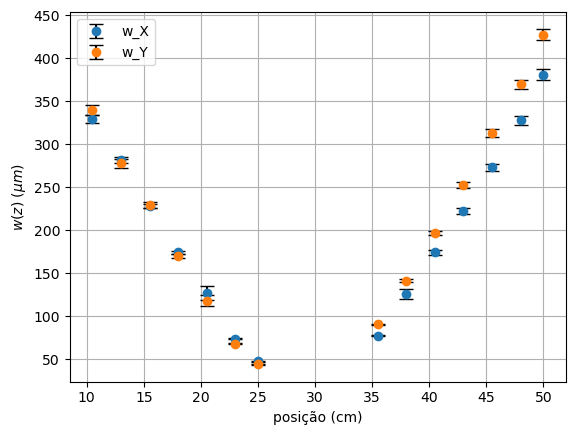

In [241]:
# Vamos plotar um exemplo:
plt.errorbar(z_325*1e2, w_X, yerr = std_wX, fmt='o', ecolor='black', capsize=5, label = 'w_X')
plt.errorbar(z_325*1e2, w_Y, yerr = std_wY, fmt='o', ecolor='black', capsize=5, label = 'w_Y')

plt.legend()
plt.grid()

plt.xlabel('posição (cm)')
plt.ylabel(r'$w(z)$ ($\mu m$)')

plt.show()

Direção X:
  Raio da cintura w0 = 89.04 µm
  Posição da cintura z0 = 281.961 mm
  Comprimento de Rayleigh zR = 55.257 mm
  Divergência = 1.611 mrad (0.0156°)

Direção Y:
  Raio da cintura w0 = 92.50 µm
  Posição da cintura z0 = 273.340 mm
  Comprimento de Rayleigh zR = 54.531 mm
  Divergência = 1.696 mrad (0.0157°)


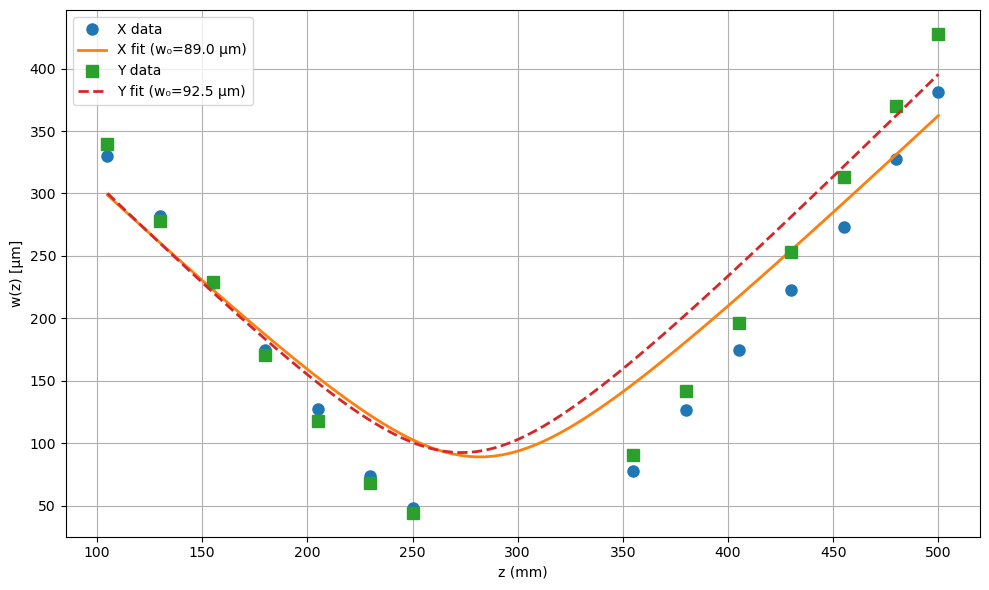

In [245]:
w0_X,w0_Y,z0_X,z0_Y,zR_X,zR_Y,divergence_X_mrad,divergence_Y_mrad,M2_X,M2_Y = gaussian_fit(w_X,w_Y,std_wX, std_wY,z_325,M2_X = M2_X, M2_Y = M2_Y )

print("Direção X:")
print(f"  Raio da cintura w0 = {w0_X*1e6:.2f} µm")
print(f"  Posição da cintura z0 = {z0_X*1e3:.3f} mm")
print(f"  Comprimento de Rayleigh zR = {zR_X*1e3:.3f} mm")
print(f"  Divergência = {divergence_X_mrad:.3f} mrad ({np.degrees(divergence_X):.4f}°)")

print("\nDireção Y:")
print(f"  Raio da cintura w0 = {w0_Y*1e6:.2f} µm")
print(f"  Posição da cintura z0 = {z0_Y*1e3:.3f} mm")
print(f"  Comprimento de Rayleigh zR = {zR_Y*1e3:.3f} mm")
print(f"  Divergência = {divergence_Y_mrad:.3f} mrad ({np.degrees(divergence_Y):.4f}°)")

# Plot
z_fit = np.linspace(z_325.min(), z_325.max(), 100)
plt.figure(figsize=(10, 6))
plt.plot(z_325*1e3, w_X, 'o', label='X data', markersize=8)
plt.plot(z_fit*1e3, gaussian_beam(z_fit, w0_X,z0_X,zR_X)*1e6, '-', label=f'X fit (w₀={w0_X*1e6:.1f} µm)', linewidth=2)
plt.plot(z_325*1e3, w_Y, 's', label='Y data', markersize=8)
plt.plot(z_fit*1e3, gaussian_beam(z_fit, w0_Y,z0_Y,zR_Y)*1e6, '--', label=f'Y fit (w₀={w0_Y*1e6:.1f} µm)', linewidth=2)
plt.xlabel('z (mm)')
plt.ylabel('w(z) [µm]')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

In [249]:
gaussian_beam(250e-3, w0_X,z0_X,zR_X)*1e6
## Não corresponde as medições.

102.85625442215775